### Basic Chatbot with LangGraph (StateGraph - Graph API)

In [10]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [11]:
class State(TypedDict):
    # Messages have the type list. The add_messages function
    # in the annoatation defines how this state key should be updated
    # (in this case, it appends messages to the list , rather than overwritting them)
    messages:Annotated[list, add_messages]

In [12]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [ ]:
groq_api_key = os.getenv('GROQ_API_KEY')

from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-20b", groq_api_key=groq_api_key)

In [13]:
## Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [14]:
llm.invoke("What is America?")

AIMessage(content='**America** can refer to a few related but distinct ideas, depending on the context:\n\n| What it usually means | What it refers to | Key points |\n|------------------------|-------------------|------------|\n| **The Americas (continents)** | The two large landmasses that together form the western hemisphere: **North America** (Canada, the United States, Mexico, and the countries of Central America) and **South America** (Argentina, Brazil, Chile, etc.). | •\u202fTogether they’re called *the Americas* to emphasize the shared history of European colonisation and indigenous cultures. <br>•\u202fGeographically they’re separated by the Isthmus of Panama but culturally and historically they’ve interacted for millennia. |\n| **The United States of America (USA)** | A sovereign nation in North America consisting of 50 states, a federal district (Washington, D.C.), and several territories. | •\u202fFounded 1776 after declaring independence from Britain.<br>•\u202fOften simpl

In [15]:
graphbuilder = StateGraph(State)

In [16]:
# Adding Nodes
graphbuilder.add_node("llmchatbot",chatbot)

#Adding edges
graphbuilder.add_edge(START,"llmchatbot")
graphbuilder.add_edge("llmchatbot",END)

graph = graphbuilder.compile()

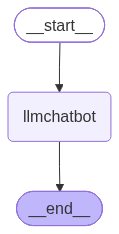

In [17]:
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [18]:
graph.invoke({"messages":"Hi"})

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='22ff3e20-1076-4c62-87c2-7cc54529d041'),
  AIMessage(content='Hello! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi". We should respond politely. Probably a greeting.'}, response_metadata={'token_usage': {'completion_tokens': 36, 'prompt_tokens': 72, 'total_tokens': 108, 'completion_time': 0.041230173, 'completion_tokens_details': {'reasoning_tokens': 16}, 'prompt_time': 0.017402692, 'prompt_tokens_details': None, 'queue_time': 0.244159329, 'total_time': 0.058632865}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_a8c584dda7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1b31f-fc8c-766a-b8a6-f742d58d2eb7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 36, 'total_tokens': 108, 'output_token_details': {'reasoning': 16}})]}

### Chatbot with Tool

In [20]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results = 2)
tool.invoke("What is Recent AI News")

{'query': 'What is Recent AI News',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.youtube.com/watch?v=TVRCcMlvR10',
   'title': 'AI News: 24 Things You Need To Know This Week',
   'content': "Here's the AI news you probably missed this week! Anthropic introduces Claude Duet, AI-powered cybersecurity threats are raising serious concerns, and OpenAI continues rolling out new updates. Plus, Ideogram's new vector model, ElevenLabs Chimera, and a rapid-fire roundup of the latest AI advancements.\n\nSharing the latest news and advancements in AI\n\nDiscover More:\n🛠️ Explore AI Tools & News: \n📰 Weekly Newsletter: [...] Time Stamps:\n00:00 Claude Duet: Anthropic's New AI Agent\n02:47 Major AI Cybersecurity Threats\n07:54 Hyperagent (Sponsor)\n08:57 OpenAI's Latest Updates\n12:25 Ideogram's New AI Vector Generator\n13:24 ElevenLabs Chimera: AI Video Generation\n16:02 Perplexity's New AI Models and Computer\n17:14 Websites Are Blocking AI Agent

In [21]:
#Custom Tool function
def multiply(a:int, b:int)->int:
    """
    Mulitply a and b

    a(int): first interger
    b(int):second integer

    Returns:
    int: output int

    """
    return a*b

In [22]:
tools = [tool, multiply] #putting them in list

In [25]:
llm_with_tools = llm.bind_tools(tools)

In [26]:
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.1', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000276B3140280>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000276B3140190>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and 

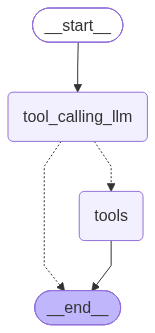

In [28]:
#StateGraph

from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

#Node definition 
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

#Node
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

#edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

#compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [30]:
reponse = graph.invoke({"messages":"Hey How are you"})

In [31]:
for m in reponse["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hey How are you
================================== Ai Message ==================================

Hey! I’m doing great—thanks for asking. How can I help you today?


In [36]:
response = graph.invoke({"messages":"What is the weather now in utica, newyork"})

In [37]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the weather now in utica, newyork
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_b97078c9-9672-4836-b76d-766dcb43c429)
 Call ID: fc_b97078c9-9672-4836-b76d-766dcb43c429
  Args:
    query: current weather in Utica, New York
    search_depth: basic
================================= Tool Message =================================
Name: tavily_search

{"query": "current weather in Utica, New York", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.almanac.com/weather/longrange/ny/Utica", "title": "Long-Range Weather Forecast for Utica, NY", "content": "November 2026 Long Range Weather Forecast for Northeast\n| Dates | Weather Conditions |\n --- |\n| Nov 1-7 | Snow showers north, sunny south; cold |\n| Nov 8-14 | Rainy periods, mild |\n| Nov 15-24 | Rain and snow showers, chilly |\n| Nov 25-30 | R

In [46]:
response = graph.invoke({"messages":"What is 2 multiplied 3"})

In [47]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is 2 multiplied 3
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_7f326303-0b89-486d-969a-b087dccde640)
 Call ID: fc_7f326303-0b89-486d-969a-b087dccde640
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6


In [48]:
response = graph.invoke({"messages":"What is recent ai news and then multiply 3 by 4"})

In [ ]:
for m in response["messages"]:
    m.pretty_print()   #it doesnt execute both tools when we ask, the reason is - its getting executed after calling single tool to end, not revert back to llm to decide 

================================ Human Message =================================

What is recent ai news and then multiply 3 by 4
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_a3adcf8e-5f51-46c1-b60a-62a2951807c2)
 Call ID: fc_a3adcf8e-5f51-46c1-b60a-62a2951807c2
  Args:
    query: latest AI news 2026 November
    search_depth: basic
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news 2026 November", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.ohiotechnews.com/you-need-to-be-paying-attention-to-ohio-tech-november-2026", "title": "You need to be paying attention to Ohio tech: November 2026", "content": "Wright State is now hosting the Air Force Research Laboratory’s AI autonomy team, a digital transformation unit and Air Force Institute of Technology programs, the latest step in a pa

### ReAct Agent Architecture

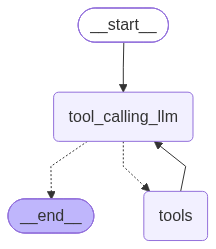

In [52]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

#Node Architecture
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

#Nodes
react_builder = StateGraph(State)
react_builder.add_node("tool_calling_llm",tool_calling_llm)
react_builder.add_node("tools",ToolNode(tools))

#Edges
react_builder.add_edge(START,"tool_calling_llm")
react_builder.add_conditional_edges("tool_calling_llm",tools_condition)
react_builder.add_edge("tools","tool_calling_llm")

#Compile
graph=react_builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [54]:
response = graph.invoke({"messages":"Whats the weather now in utica and multiply 5 by 5"})

In [56]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Whats the weather now in utica and multiply 5 by 5
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_09e05537-daf2-4666-9d67-ce4e50dbf0da)
 Call ID: fc_09e05537-daf2-4666-9d67-ce4e50dbf0da
  Args:
    query: current weather in Utica NY
    search_depth: basic
    topic: general
================================= Tool Message =================================
Name: tavily_search

{"query": "current weather in Utica NY", "follow_up_questions": null, "answer": null, "images": [], "results": [{"title": "Weather in Utica, NY", "url": "https://www.weatherapi.com/", "content": "{'location': {'name': 'Utica', 'region': 'New York', 'country': 'United States of America', 'lat': 43.1008, 'lon': -75.2331, 'tz_id': 'America/New_York', 'localtime_epoch': 1794084823, 'localtime': '2026-11-07 15:53'}, 'current': {'last_updated_epoch': 1794084300, 'last_updated

In [57]:
response2 = graph.invoke({"messages":"Give me the Telangana news of yesterday"})

In [58]:
for m in response2["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me the Telangana news of yesterday
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_a5726862-7135-4b97-87bc-8f4250492715)
 Call ID: fc_a5726862-7135-4b97-87bc-8f4250492715
  Args:
    query: Telangana news yesterday
    search_depth: basic
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "Telangana news yesterday", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://telanganatoday.com/cartoon-today-on-november-6-2026", "title": "Cartoon Today on November 6, 2026", "content": "Cartoon Today on November 6, 2026. By Telangana Today. Published Date - 6 November 2026, 08:00 AM. Cartoon Today on November 6, 2026.", "score": 0.493336, "published_date": "Fri, 06 Nov 2026 20:00:00 GMT", "raw_content": null, "id": "33e238-00"}, {"url"

## Adding memory in Agentic Graph

In [60]:
response = graph.invoke({"messages":"Hey My name is Sam"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hey My name is Sam
================================== Ai Message ==================================

Nice to meet you, Sam! How can I help you today?


In [61]:
response = graph.invoke({"messages":"Whats my name"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Whats my name
================================== Ai Message ==================================

I’m sorry, but I don’t have that information.


As it doesnt save the information we create the memory for it

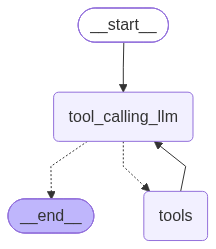

In [78]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory=MemorySaver()

#Node Architecture
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

#Nodes
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

#Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools","tool_calling_llm")

#Compile
graph = builder.compile(checkpointer = memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [79]:
# create a configurable thread of a chat 

config= {"configurable":{"thread_id":"1"}}

response = graph.invoke({"messages":"Hi my name is Sumanth"}, config=config)

response

{'messages': [HumanMessage(content='Hi my name is Sumanth', additional_kwargs={}, response_metadata={}, id='4838fc9c-b499-4da2-9133-801491258b64'),
  AIMessage(content='Hello Sumanth! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'User just introduced themselves. Likely want a friendly response.'}, response_metadata={'token_usage': {'completion_tokens': 36, 'prompt_tokens': 358, 'total_tokens': 394, 'completion_time': 0.036312746, 'completion_tokens_details': {'reasoning_tokens': 13}, 'prompt_time': 0.005849371, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.083700468, 'total_time': 0.042162117}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_ed70b23331', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1b807-ff87-72a6-b1b7-5aa07629ec3b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 358, 'output_tokens': 36, 'total_tokens': 394, 'input_tok

In [80]:
response = graph.invoke({"messages":"Hey whats my name?"}, config=config)

In [81]:
response["messages"][-1].content

'You said your name is Sumanth!'

In [83]:
response = graph.invoke({"messages":"do you remember my name?"}, config=config)

response["messages"][-1].content

'Yes, I remember—your name is Sumanth. If there’s anything else you’d like to talk about or need help with, just let me know!'

### Streaming

Synchronous

One task waits until its operation finishes before continuing.

Asynchronous

When one task is waiting, other tasks can make progress. (waiting for the response from the api, and simultaneously or progressively python run other calls)

Streaming

You receive output progressively instead of waiting for the complete output.

In [84]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [85]:
def Superbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

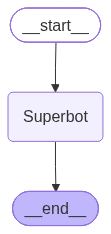

In [88]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(State)

#node
builder.add_node("Superbot", Superbot)

#edge
builder.add_edge(START,"Superbot")
builder.add_edge("Superbot",END)

#Compile
graph = builder.compile(checkpointer = memory)

display(Image(graph.get_graph().draw_mermaid_png()))

In [90]:
#Invocation
config = {"configurable":{"thread_id":"1"}}

In [91]:
graph.invoke({"messages":"Hey How are you?"}, config)

{'messages': [HumanMessage(content='Hey How are you?', additional_kwargs={}, response_metadata={}, id='bbb6ab81-a599-456d-a24b-13b61009f988'),
  AIMessage(content='Hey! I’m doing great, thanks for asking. How about you? Anything interesting going on?', additional_kwargs={'reasoning_content': 'The user says "Hey How are you?" It\'s a casual greeting. I should respond politely. Maybe ask how they are. It\'s a simple conversation.'}, response_metadata={'token_usage': {'completion_tokens': 60, 'prompt_tokens': 76, 'total_tokens': 136, 'completion_time': 0.062053926, 'completion_tokens_details': {'reasoning_tokens': 31}, 'prompt_time': 0.003676812, 'prompt_tokens_details': None, 'queue_time': 0.030401461, 'total_time': 0.065730738}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_3023a70d60', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1b8b0-6876-750a-be9e-32028c84b93b-0', tool_calls=[], invalid_tool_calls=[

Methods: .stream() and astream()

- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

- **values** : This streams the full state of the graph after each node is called.
- **updates** : This streams updates to the state of the graph after each node is called.

In [97]:
#create a thread
config = {"configurable": {"thread_id":"4"}}

for chunk in graph.stream({"messages":"Hey How are you?"}, config, stream_mode="updates"):
    print(chunk)

{'Superbot': {'messages': [AIMessage(content='Hey! I’m doing great—just ready to dive into whatever you need. How’s it going with you?', additional_kwargs={'reasoning_content': "The user repeats the same greeting. They want a response. I should respond politely, maybe mention I'm fine. They might want a casual chat. I'll respond friendly."}, response_metadata={'token_usage': {'completion_tokens': 66, 'prompt_tokens': 127, 'total_tokens': 193, 'completion_time': 0.069059134, 'completion_tokens_details': {'reasoning_tokens': 34}, 'prompt_time': 0.00870501, 'prompt_tokens_details': None, 'queue_time': 0.083507766, 'total_time': 0.077764144}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_8b41efc9a3', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1b8b5-89ab-761a-aec3-9ffb11133f80-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 127, 'output_tokens': 66, 'total_tokens': 193, 'output_t

In [99]:
#create a thread
config = {"configurable": {"thread_id":"5"}}

for chunk in graph.stream({"messages":"Hey How are you?"}, config, stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hey How are you?', additional_kwargs={}, response_metadata={}, id='ebd4b5c8-96b9-4375-84c8-05b56ccb29fd')]}
{'messages': [HumanMessage(content='Hey How are you?', additional_kwargs={}, response_metadata={}, id='ebd4b5c8-96b9-4375-84c8-05b56ccb29fd'), AIMessage(content="Hey! I'm just a bunch of code, so I don't have feelings, but I'm here and ready to help you. How can I assist you today?", additional_kwargs={'reasoning_content': 'User: "Hey How are you?" Probably respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 53, 'prompt_tokens': 76, 'total_tokens': 129, 'completion_time': 0.057991984, 'completion_tokens_details': {'reasoning_tokens': 13}, 'prompt_time': 0.005189968, 'prompt_tokens_details': None, 'queue_time': 0.002836661, 'total_time': 0.063181952}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d6de37e6be', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}

In [102]:
config = {"configurable":{"thread_id":"6"}}

async for chunk in graph.astream({"messages":"Hey How are you?"}, config):
    print(chunk)

{'Superbot': {'messages': [AIMessage(content='Hey! I’m doing great—thanks for asking. How can I help you today?', additional_kwargs={'reasoning_content': 'We have a user asking "Hey How are you?" The user is greeting. We should respond politely. The user is not asking any policy violation. We should respond as per guidelines. Probably just a friendly answer.'}, response_metadata={'token_usage': {'completion_tokens': 71, 'prompt_tokens': 76, 'total_tokens': 147, 'completion_time': 0.077164945, 'completion_tokens_details': {'reasoning_tokens': 44}, 'prompt_time': 0.008820097, 'prompt_tokens_details': None, 'queue_time': 0.202021894, 'total_time': 0.085985042}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_80501ff3a1', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1b8d9-1ec8-727b-8357-4089c49c98b0-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 76, 'output_tokens': 71, 'total_toke

In [103]:
config = {"configurable":{"thread_id":"7"}}

async for chunk in graph.astream({"messages":"Hey How are you?"}, config, stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hey How are you?', additional_kwargs={}, response_metadata={}, id='56cdc9d2-70c1-4f8b-afaf-e694f45a9d21')]}
{'messages': [HumanMessage(content='Hey How are you?', additional_kwargs={}, response_metadata={}, id='56cdc9d2-70c1-4f8b-afaf-e694f45a9d21'), AIMessage(content='Hey! I’m doing great—thanks for asking. How can I help you today?', additional_kwargs={'reasoning_content': 'User: "Hey How are you?" It\'s a friendly greeting. We should respond politely. Probably say "I\'m fine, thanks. How can I help?"'}, response_metadata={'token_usage': {'completion_tokens': 59, 'prompt_tokens': 76, 'total_tokens': 135, 'completion_time': 0.078357555, 'completion_tokens_details': {'reasoning_tokens': 32}, 'prompt_time': 0.00372379, 'prompt_tokens_details': None, 'queue_time': 0.241547234, 'total_time': 0.082081345}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_a8c584dda7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'mo

In [104]:
config = {"configurable": {"thread_id": "8"}}

async for event in graph.astream_events({"messages":["Hi My name is Krish and I like to play cricket"]},config):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a1b8df-fdcc-7527-aeee-e5145956cc86', 'metadata': {'thread_id': '8', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Krish and I like to play cricket', additional_kwargs={}, response_metadata={}, id='3fe73a5e-c2d7-47f9-8b15-e7e874ea9ecd')]}}, 'name': 'Superbot', 'tags': ['graph:step:1'], 'run_id': '01a1b8df-fdda-742a-a995-5b5bfa258409', 'metadata': {'thread_id': '8', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'Superbot', 'langgraph_triggers': ('branch:to:Superbot',), 'langgraph_path': ('__pregel_pull', 'Superbot'), 'langgraph_checkpoint_ns': 'Superbot:e47c85f6-e035-3280-d849-83e69a328721'}, 'parent_ids': ['01a1b8df-fdcc-7527-aeee-e5145956cc86']}
{'event': 'on_chain_stream', 'run_id': '01a1b8df-fdda-742a-a995

### Human in the loop

In [ ]:
from typing_extensions import TypedDict
from typing import Annotated
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages:Annotated[list, add_messages]


In [21]:
#Tools
from langgraph.types import Command, interrupt
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver


@tool
def human_in_the_loop(query:str)->str:
    """Human assistance in the loop"""
    human_response = interrupt({"query":query})
    return human_response["data"]

from langchain_tavily import TavilySearch
tavily = TavilySearch(max_results = 2)

tools = [tavily, human_in_the_loop]
llm_with_tools = llm.bind_tools(tools)

#Node Functionality
def chatbot(state:State):
    # Because we will be interrupting during tool execution,
    # we disable parallel tool calling to avoid repeating any
    # tool invocations when we resume.
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

###Graph
#nodes
builder = StateGraph(State)
builder.add_node("tool_calling_llm",chatbot)
builder.add_node("tools",ToolNode(tools))

#edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",tools_condition)
builder.add_edge("tools","tool_calling_llm")

memory = MemorySaver()
graph = builder.compile(checkpointer = memory)


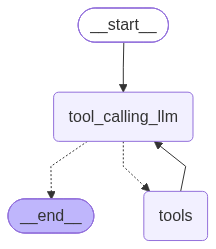

In [22]:
from IPython.display import Image, display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    # This requires some extra dependencies and is optional
    pass

In [27]:
config = {"configurable":{"thread_id":"1"}}

In [29]:
response = graph.invoke({"messages":"Hey provide me some info about how to learn about langgraph"},config)

In [30]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hey provide me some info about how to learn about langgraph
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_97f46858-c478-40d8-89c9-0043e3b6a2f0)
 Call ID: fc_97f46858-c478-40d8-89c9-0043e3b6a2f0
  Args:
    query: LangGraph learn resources tutorial
    search_depth: basic
    topic: general
================================= Tool Message =================================
Name: tavily_search

{"query": "LangGraph learn resources tutorial", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://github.com/langchain-ai/langgraph-101", "title": "GitHub - langchain-ai/langgraph-101: Learn about the fundamentals of LangGraph through a series of notebooks · GitHub", "content": "### Resources\n\n LangChain Documentation - Complete LangChain reference\n LangGraph Documentation - LangGraph guides and API reference\n De

In [55]:
config = {"configurable":{"thread_id":"4"}}

In [56]:
response = graph.invoke({"messages":"Hey say me about ai/ml engineer or ai engineer and seek assistance from me before giving me the final output about it"},config)

In [57]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hey say me about ai/ml engineer or ai engineer and seek assistance from me before giving me the final output about it
================================== Ai Message ==================================
Tool Calls:
  human_in_the_loop (fc_3794bf7b-adb3-478b-9c0b-061174535cb4)
 Call ID: fc_3794bf7b-adb3-478b-9c0b-061174535cb4
  Args:
    query: Clarify what specific aspects of AI/ML engineer role user wants to know: responsibilities, skills, career path, salary, education, industry trends, etc.


In [50]:
print(type(graph))
print(graph.get_state(config).tasks)

<class 'langgraph.graph.state.CompiledStateGraph'>
()


In [58]:
from langgraph.types import Command

human_response="Give me clear difference between ai/ml engineer and ai engineer"

human_command = Command(resume ={"data":human_response})

response = graph.invoke(human_command, config)

In [59]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hey say me about ai/ml engineer or ai engineer and seek assistance from me before giving me the final output about it
================================== Ai Message ==================================
Tool Calls:
  human_in_the_loop (fc_3794bf7b-adb3-478b-9c0b-061174535cb4)
 Call ID: fc_3794bf7b-adb3-478b-9c0b-061174535cb4
  Args:
    query: Clarify what specific aspects of AI/ML engineer role user wants to know: responsibilities, skills, career path, salary, education, industry trends, etc.
================================= Tool Message =================================
Name: human_in_the_loop

Give me clear difference between ai/ml engineer and ai engineer
================================== Ai Message ==================================

**AI/ML Engineer vs. AI Engineer – The Key Distinctions**

| Aspect | **AI/ML Engineer** | **AI Engineer** |
|--------|-------------------|-----------------|
| **Core Focu

In [ ]:
input = "Hey how are you, take my assistance about my mood today and behave accordingly"
config = {"configurable":{"thread_id":"a1"}}

events = graph.stream({"messages":input}, config, stream_mode="values")

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()